In [2]:
# Отток клиентов телеком

import kagglehub

# качаем дата сет
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

E:\Projects\Python\MashineLeaning\HomeWork1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Home\.cache\kagglehub\datasets\blastchar\telco-customer-churn\versions\1


In [3]:
#  заполняем дата сет
import pandas as pd
data = pd.read_csv(path+'/'+'WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [4]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# ищем колонки которые по сути цифровые, а по факту str
for col in data.select_dtypes(include='str').columns:
    # Пытаемся преобразовать в число, игнорируя ошибки
    converted = pd.to_numeric(data[col], errors='coerce')
    n_errors = converted.isna().sum()
    if n_errors < len(data):  # Если хотя бы часть значений — числа
        print(f"  {col}: можно преобразовать (ошибок: {n_errors})")

  TotalCharges: можно преобразовать (ошибок: 11)


In [6]:
# меняем им тип
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
print(data[data['TotalCharges'].isna()][['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No


In [7]:
# попробуем понять что какие значения MonthlyCharges у тех кто был всего месяц что бы не удалять записи и не ставить пустые значения.
tenure_1 = data[data['tenure'] == 1]
tenure_1['TotalCharges']

0       29.85
20      39.65
22      20.15
27      30.20
33      20.20
        ...  
6979    24.20
7010    74.45
7016    49.95
7018    70.65
7032    75.75
Name: TotalCharges, Length: 613, dtype: float64

In [8]:
# исходя из увиденного предположим что они были всего один месяц. Заполняем  tenure=1 и  TotalChargeы = MonthlyCharges
to_fill_idx = data[data['TotalCharges'].isna()].index
data.loc[to_fill_idx, 'tenure'] = 1
data.loc[to_fill_idx, 'TotalCharges'] = data.loc[to_fill_idx, 'MonthlyCharges']

In [9]:
#удаляем CustomerID она лишняя
data = data.drop(columns=['customerID'])

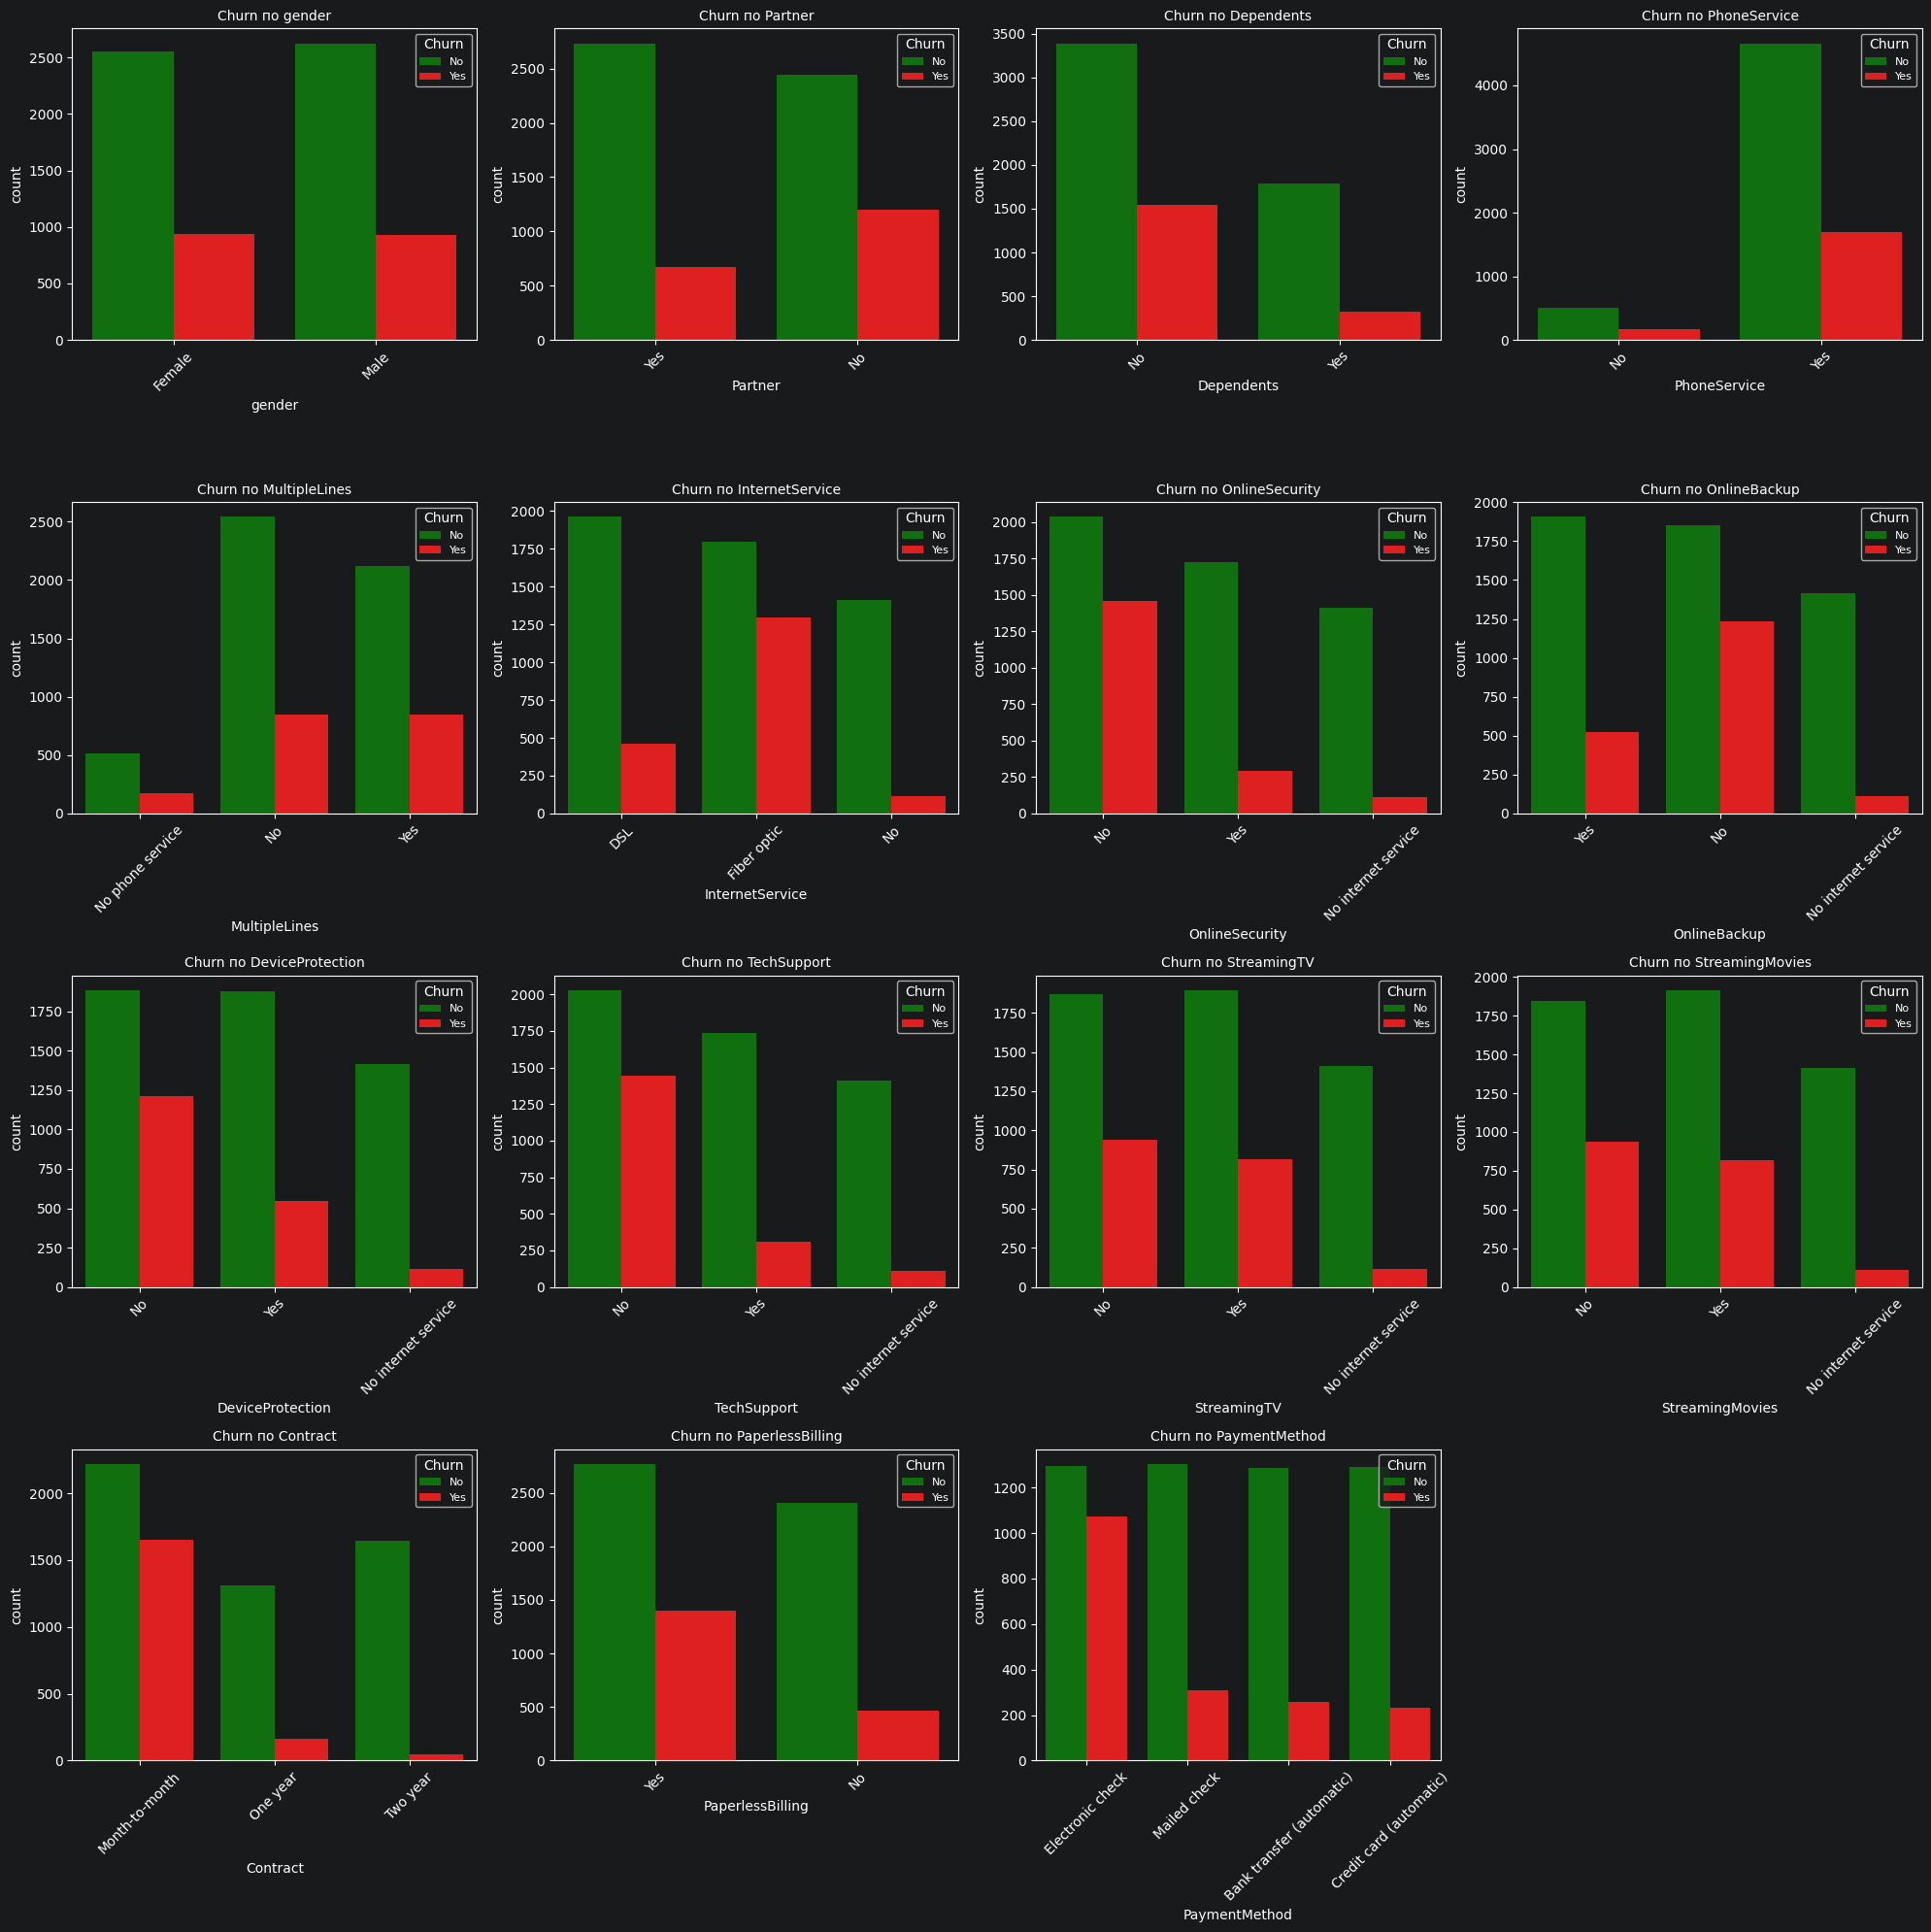

In [10]:
# Рисуем график зависимостей целевой переменной от параметров.
import matplotlib.pyplot as plt
import seaborn as sns


cat_cols = data.select_dtypes(exclude=['number']).columns.drop('Churn')


n_features = len(cat_cols)
n_rows = (n_features + 3) // 4
fig, axes = plt.subplots(n_rows, 4, figsize=(20, 5 * n_rows))
axes = axes.flatten()


for idx, feature in enumerate(cat_cols):
    sns.countplot(
        data=data,
        x=feature,
        hue='Churn',
        ax=axes[idx],
        palette={'No': 'green', 'Yes': 'red'}
    )
    axes[idx].set_title(f'Churn по {feature}', fontsize=10)
    axes[idx].tick_params(axis='x', rotation=45)
    axes[idx].legend(title='Churn', fontsize=8)


for idx in range(len(cat_cols), len(axes)):
    axes[idx].set_visible(False)

plt.tight_layout()
plt.show()

In [11]:
# признаки под удаление их влияние либо почти нулевое, либо незначительное (уменьшаем размерность)
features_to_drop = [
    'gender',
    'PhoneService',
    'MultipleLines',
    'StreamingTV',
    'StreamingMovies'
]


data = data.drop(columns=features_to_drop)

In [12]:
# Преобразуем категоральные в числовые, но разделим на бинарные и многоклассовые
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
# бинарные признаки
binary_features = [
    'Partner', 'Dependents', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'PaperlessBilling'
]


for col in binary_features:
    data[col] = le.fit_transform(data[col])

data['Churn'] = le.fit_transform(data['Churn'])

# многоклассовые признаки One-Hot Encoding
multi_features = ['Contract', 'InternetService', 'PaymentMethod']
data = pd.get_dummies(data, columns=multi_features, drop_first=True, dtype=int)


In [13]:
# разбиваем данные на train и test
from sklearn.model_selection import train_test_split


X = data.drop(columns=['Churn'])
y = data['Churn']


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [14]:
# Модели из коробки с дефолтными параметрами
# Модели из коробки с дефолтными параметрами
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
# ИСПРАВЛЕННЫЙ ИМПОРТ: добавили precision, recall и f1
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score
import time
import pandas as pd

# Создаём словарь с моделями
models = {
    'Sklearn GBM': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1)
}

# Словарь для результатов взял стандартные accuracy и roc_auc. Добавил precision recall и F1
results = {}

# Обучаем каждую модель и оцениваем её качество
for name, model in models.items():
    print(f"\n--- Обучение модели: {name} ---")

    start_time = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start_time

    # Предсказания на тестовой выборке
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    # Считаем метрики (ДОБАВИЛИ Precision, Recall, F1)
    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # Сохраняем результаты
    results[name] = {
        'Accuracy': accuracy,
        'ROC_AUC': roc_auc,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'Time (sec)': train_time
    }

    print(f"  Accuracy:  {accuracy:.4f}")
    print(f"  ROC_AUC:   {roc_auc:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall:    {recall:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print(f"  Время:     {train_time:.2f} сек")

# Выводим итоговую таблицу для сравнения
results_df = pd.DataFrame(results).T
print("\n\n--- Итоговое сравнение моделей (параметры по умолчанию) ---")
print(results_df.round(4))

#Все модели из коробки хорошо предсказывает лояльных (останутся). Но из-за дисбаланса в churn (73/27) по показателям Recall плохо видит уходящих. Sklearn GBM лидер среди все моделей.  Получается ее параметры наимболее сбалансированы для этих данных.


--- Обучение модели: Sklearn GBM ---
  Accuracy:  0.7979
  ROC_AUC:   0.8394
  Precision: 0.6611
  Recall:    0.4902
  F1-score:  0.5629
  Время:     0.74 сек

--- Обучение модели: XGBoost ---
  Accuracy:  0.7672
  ROC_AUC:   0.8101
  Precision: 0.5711
  Recall:    0.4938
  F1-score:  0.5296
  Время:     0.55 сек

--- Обучение модели: CatBoost ---
  Accuracy:  0.7894
  ROC_AUC:   0.8317
  Precision: 0.6318
  Recall:    0.4955
  F1-score:  0.5554
  Время:     3.48 сек

--- Обучение модели: LightGBM ---
  Accuracy:  0.7785
  ROC_AUC:   0.8222
  Precision: 0.5991
  Recall:    0.5009
  F1-score:  0.5456
  Время:     2.07 сек


--- Итоговое сравнение моделей (параметры по умолчанию) ---
             Accuracy  ROC_AUC  Precision  Recall  F1-score  Time (sec)
Sklearn GBM    0.7979   0.8394     0.6611  0.4902    0.5629      0.7446
XGBoost        0.7672   0.8101     0.5711  0.4938    0.5296      0.5474
CatBoost       0.7894   0.8317     0.6318  0.4955    0.5554      3.4772
LightGBM       0.778

In [17]:
# попробуем подобрать параметры модели в худшую сторону
from sklearn.model_selection import GridSearchCV

# Создаем модель
gbm = GradientBoostingClassifier(random_state=42)

# Задаем "неправильную" сетку параметров
param_grid_wrong = {
    'n_estimators': [10, 20],          # мало деревьев
    'learning_rate': [1.0, 2.0],       # быстро учимся
    'max_depth': [10, 15],             # глубокая модель, чтобы переобучить
    'subsample': [1.0],                # нет подвыборки
    'max_features': [None]             # используем все признаки
}

# Автоматический подбор гиперпараметров
grid_wrong = GridSearchCV(
    estimator=gbm,
    param_grid=param_grid_wrong,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

# ИСПРАВЛЕНИЕ: добавляем замер времени
grid_wrong.fit(X_train, y_train)

print(f"Лучшие параметры (ошибочные): {grid_wrong.best_params_}")
print(f"Лучший ROC_AUC (CV): {grid_wrong.best_score_:.4f}")

# Оценка на тесте
best_gbm_wrong = grid_wrong.best_estimator_
y_pred = best_gbm_wrong.predict(X_test)
y_pred_proba = best_gbm_wrong.predict_proba(X_test)[:, 1]

# Считаем все метрики
accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\n--- Результаты на тесте (неправильная настройка) ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"ROC_AUC:   {roc_auc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

#Неверные настройки не улучшили Recall, а остальное ухудшили.


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Лучшие параметры (ошибочные): {'learning_rate': 1.0, 'max_depth': 15, 'max_features': None, 'n_estimators': 20, 'subsample': 1.0}
Лучший ROC_AUC (CV): 0.7868

--- Результаты на тесте (неправильная настройка) ---
Accuracy:  0.7586
ROC_AUC:   0.7868
Precision: 0.5507
Recall:    0.4938
F1-score:  0.5207


In [20]:
# Теперь для каждой модели подберем наиболее оптимальные параметры

models_config = {
    'Sklearn GBM': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.05, 0.1],
            'max_depth': [3, 5],
            'subsample': [0.8, 1.0],
            'max_features': ['sqrt', 'log2']
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.01, 0.05],
            'max_depth': [3, 5],
            'subsample': [0.7, 0.9],
            'colsample_bytree': [0.7, 0.9]
        }
    },
    'LightGBM': {
        'model': LGBMClassifier(random_state=42, verbose=-1),
        'params': {
            'n_estimators': [100, 200],
            'learning_rate': [0.01, 0.05],
            'max_depth': [3, 5],
            'subsample': [0.7, 0.9],
            'colsample_bytree': [0.7, 0.9]
        }
    },
    'CatBoost': {
        'model': CatBoostClassifier(random_state=42, verbose=0),
        'params': {
            'iterations': [100, 200],
            'learning_rate': [0.03, 0.1],
            'depth': [3, 5],
            'l2_leaf_reg': [1, 3]
        }
    }
}

results_tuned = {}

for name, config in models_config.items():
    print(f"\n{'='*50}")
    print(f"Настройка модели: {name}")
    print(f"{'='*50}")

    start_time = time.time()

    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=5,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )

    grid.fit(X_train, y_train) # Используем X_train_reduced, если вы удаляли признаки
    elapsed_time = time.time() - start_time

    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test) # Используем X_test_reduced
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    # Считаем метрики
    accuracy = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)


    results_tuned[name] = {
        'Best Params': grid.best_params_,
        'CV ROC_AUC': grid.best_score_,
        'Test Accuracy': accuracy,
        'Test ROC_AUC': roc_auc,
        'Test Precision': precision,
        'Test Recall': recall,
        'Test F1-score': f1,
        'Time (sec)': elapsed_time
    }

    print(f"Лучшие параметры: {grid.best_params_}")
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"ROC_AUC:   {roc_auc:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

# Итоговая таблица
print("\n\n" + "="*80)
print("ИТОГОВОЕ СРАВНЕНИЕ ПОСЛЕ НАСТРОЙКИ ГИПЕРПАРАМЕТРОВ")
print("="*80)


results_df = pd.DataFrame({
    name: {
        'Test Accuracy': res['Test Accuracy'],
        'Test ROC_AUC': res['Test ROC_AUC'],
        'Test Precision': res['Test Precision'],
        'Test Recall': res['Test Recall'],
        'Test F1-score': res['Test F1-score']
    }
    for name, res in results_tuned.items()
}).T

print(results_df.round(4))

# Победитель Cat_Boost. Recall все равно низкий для все моделей.


Настройка модели: Sklearn GBM
Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 3, 'max_features': 'sqrt', 'n_estimators': 100, 'subsample': 0.8}
Accuracy:  0.7984
ROC_AUC:   0.8447
Precision: 0.6627
Recall:    0.4902
F1-score:  0.5635

Настройка модели: XGBoost
Лучшие параметры: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.9}
Accuracy:  0.7974
ROC_AUC:   0.8440
Precision: 0.6618
Recall:    0.4848
F1-score:  0.5597

Настройка модели: LightGBM
Лучшие параметры: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.7}
Accuracy:  0.7970
ROC_AUC:   0.8432
Precision: 0.6658
Recall:    0.4724
F1-score:  0.5527

Настройка модели: CatBoost
Лучшие параметры: {'depth': 3, 'iterations': 100, 'l2_leaf_reg': 3, 'learning_rate': 0.1}
Accuracy:  0.8017
ROC_AUC:   0.8456
Precision: 0.6644
Recall:    0.5116
F1-score:  0.5780


ИТОГОВОЕ СРАВНЕНИЕ ПОСЛЕ НАСТРОЙКИ ГИПЕРПАРАМЕТРОВ
             Test 

In [21]:
# Возьмем лушую модель и уменьшим порог до 0.3-0.4


cat_model = CatBoostClassifier(
    iterations=100,
    depth=3,
    l2_leaf_reg=3,
    learning_rate=0.1,
    random_state=42,
    verbose=0
)
cat_model.fit(X_train, y_train)

# Получаем вероятности на тесте
y_proba = cat_model.predict_proba(X_test)[:, 1]

# Задаём пороги для проверки
thresholds = [0.5, 0.4, 0.3, 0.2]
results_thresholds = []

# Считаем метрики для каждого порога
for thresh in thresholds:
    # Превращаем вероятности в классы (1, если вероятность >= порога)
    y_pred_custom = (y_proba >= thresh).astype(int)

    # Считаем метрики
    acc = accuracy_score(y_test, y_pred_custom)
    prec = precision_score(y_test, y_pred_custom)
    rec = recall_score(y_test, y_pred_custom)
    f1 = f1_score(y_test, y_pred_custom)

    # Сколько клиентов мы отправим в "зону риска"
    n_flagged = y_pred_custom.sum()
    n_total = len(y_pred_custom)

    results_thresholds.append({
        'Порог': thresh,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-score': f1,
        'Клиентов в зоне риска': f"{n_flagged} ({n_flagged/n_total*100:.1f}%)"
    })

# 5. Выводим результаты
df_thresholds = pd.DataFrame(results_thresholds)
print("Влияние порога классификации на метрики (CatBoost):")
print(df_thresholds.to_string(index=False))

#Recall вырос. Так что задачу по анализу потенциально уходящих мы решаем путем уменьшения порога.


Влияние порога классификации на метрики (CatBoost):
 Порог  Accuracy  Precision   Recall  F1-score Клиентов в зоне риска
   0.5  0.801704   0.664352 0.511586  0.578046           432 (20.4%)
   0.4  0.791292   0.599668 0.643494  0.620808           602 (28.5%)
   0.3  0.761950   0.536709 0.755793  0.627683           790 (37.4%)
   0.2  0.715570   0.480080 0.859180  0.615974          1004 (47.5%)
